# **Лабораторная работа №1**

## Реализация алгоритма линейной регрессии на Python

### Описание задачи

1. Исходные данные представляют собой CSV файл с двумя столбцами
2. Реализовать чтение данных из файла
3. Вывести статистическую информацию о используемых данных (количество, min, max, среднее) по каждому из столбцов
4. Используя библиотеку Matplotlib вывести изображение исходных точек
5. Реализовать алгоритм метода наименьших квадратов и вычислить параметры регрессионной прямой.
6. Используя библиотеку Matplotlib и полученное в п.3 изображение отрисовать на изображении другим цветом полученную прямую
7. Используя полученное в п.5 изображение, отрисовать и заштриховать квадраты ошибок 


 *Общие замечания: программа должна позволять работать с другими входными файлами, программа должна позволять выбрать какой из входных столбцов выбрать в качестве Х а какой в качестве У(в случае если столбцов больше 2), по завершению программы должны одновременно видны все 3 изображения (п.3, п.5, п.6)*

### 1. Реализация считывания данных из CSV файла

In [90]:
import os

#### Создание собственного класса для:
1. Корректного считывания данных из CSV файла
2. Разделения данных на X - призанки и y - целевые значения
3. Подсчета статистик по столбцам

In [91]:
class DataExtractor:
    def __init__(self, file_path='lab1_DS.csv'):
        self.file_path = file_path
        self.header = None
        self.rows = None

    def _check_file(self):
        '''Проверка файла на корректность'''
        if not os.path.exists(self.file_path):
            raise FileNotFoundError(f'Файл не найден по пути {self.file_path}')

        if not self.file_path.endswith('.csv'):
            raise ValueError(f'Ожидался .csv, получен: {self.file_path}')

        if os.path.getsize(self.file_path) == 0:
            raise ValueError('Файл пустой')

    def read_csv(self, has_header=True, delimeter=','):
        '''Считывание данных из .csv файла'''
        self._check_file()

        rows = []
        with open(self.file_path, 'r', encoding='utf-8') as file:
            lines = file.read().splitlines()

        if not lines:
            raise ValueError('Файл не содержит строк')

        start = 0
        
        if has_header:
            self.header = [h.strip() for h in lines[0].split(delimeter)]
            start = 1

        for i, line in enumerate(lines[start:], start=start + 1):
            line = line.strip()
            if not line:
                continue
            parts = line.split(delimeter)
            try:
                row = [float(p) for p in parts]
            except ValueError:
                raise ValueError(f'Строка {i}: не удалось преобразовать в числа: {line!r}')
            rows.append(row)

        if not rows:
            raise ValueError('Нет валидных строк с данными')

        n_cols = len(rows[0])
        for i, r in enumerate(rows, start=1):
            if len(r) != n_cols:
                raise ValueError(f'Строка {i} содержит {len(r)} столбцов, ожидалось {n_cols}')

        self.rows = rows
        return rows

    def _resolve_column(self, col):
        '''Проверка индексов колонок на корректность'''
        if isinstance(col, int):
            n_cols = len(self.rows[0])
            if not (-n_cols <= col < n_cols):
                raise IndexError(f'Индекс столбца {col} вне диапазона 0..{n_cols - 1}')
            return col if col >= 0 else n_cols + col

        if isinstance(col, str):
            if self.header is None:
                raise ValueError('Столбец задан по имени, но header отсутствует')
            if col not in self.header:
                raise KeyError(f'Столбца {col!r} нет среди {self.header}')
            return self.header.index(col)

        raise TypeError('Столбец должен быть int (индекс) или str (имя)')

    def get_xy(self, feature_column=0, target_column=1):
        '''Выделение данных X и целевых значений y'''
        if self.rows is None:
            raise RuntimeError('Сначала вызовите read_csv()')

        if isinstance(feature_column, (int, str)):
            feature_column = [feature_column]
        if not isinstance(feature_column, (list, tuple)) or len(feature_column) == 0:
            raise TypeError('feature_column должен быть int, str или непустым списком')

        fx = [self._resolve_column(c) for c in feature_column]
        ty = self._resolve_column(target_column)

        if ty in fx:
            raise ValueError('Целевой столбец не должен входить в признаки')

        if len(set(fx)) != len(fx):
            raise ValueError('Признаки содержат повторяющиеся столбцы')

        X = [[row[j] for j in fx] for row in self.rows]
        y = [row[ty] for row in self.rows]
        return X, y

    def get_stats(self):
        '''Статистики по признакам'''

        if self.rows is None:
            raise RuntimeError('Сначала вызовите read_csv()')

        n_cols = len(self.rows[0])
        stats = {}

        for j in range(n_cols):
            col = [row[j] for row in self.rows]
            name = self.header[j] if self.header else j
            stats[name] = {
                'count': len(col),
                'min':   min(col),
                'max':   max(col),
                'mean':  sum(col) / len(col),
            }
        return stats

    def print_stats(self):
        '''Вывод статистик по столбцам'''

        stats = self.get_stats()
        for name, s in stats.items():
            print(f'Столбец {name!r}: '
                f'count={s["count"]}, '
                f'min={s["min"]:.4f}, '
                f'max={s["max"]:.4f}, '
                f'mean={s["mean"]:.4f}')
        

#### Считывание данных из файла `'lab1_DS.csv'`

In [92]:
data = DataExtractor()
data.read_csv()
data.print_stats()

Столбец 'YearsExperience': count=35, min=1.1000, max=13.5000, mean=6.3086
Столбец 'Salary': count=35, min=37731.0000, max=139465.0000, mean=83945.6000


In [93]:
X, y = data.get_xy()

for i in range(len(X)):
    print(X[i], y[i])

[1.1] 39343.0
[1.3] 46205.0
[1.5] 37731.0
[2.0] 43525.0
[2.2] 39891.0
[2.9] 56642.0
[3.0] 60150.0
[3.2] 54445.0
[3.2] 64445.0
[3.7] 57189.0
[3.9] 63218.0
[4.0] 55794.0
[4.0] 56957.0
[4.1] 57081.0
[4.5] 61111.0
[4.9] 67938.0
[5.1] 66029.0
[5.3] 83088.0
[5.9] 81363.0
[6.0] 93940.0
[6.8] 91738.0
[7.1] 98273.0
[7.9] 101302.0
[8.2] 113812.0
[8.7] 109431.0
[9.0] 105582.0
[9.5] 116969.0
[9.6] 112635.0
[10.3] 122391.0
[10.5] 121872.0
[11.2] 127345.0
[11.5] 126756.0
[12.3] 128765.0
[12.9] 135675.0
[13.5] 139465.0


#### *Таким образом реализованы пункты 1, 2 и 3 задания*

### 2. Вывод изображения исходных точек

In [94]:
import matplotlib.pyplot as plt

In [95]:
def plot_raw(xs, y, ax=None, title='Исходные точки'):
    if xs and isinstance(xs[0], (list, tuple)):
        xs = [row[0] for row in xs]
        
    if ax is None:
        _, ax = plt.subplots()
    ax.scatter(xs, y, color='steelblue', s=20, zorder=3)
    ax.set_title(title)
    ax.set_xlabel('X')
    ax.set_ylabel('y')
    ax.grid(alpha=0.3)
    return ax

<Axes: title={'center': 'Исходные точки'}, xlabel='X', ylabel='y'>

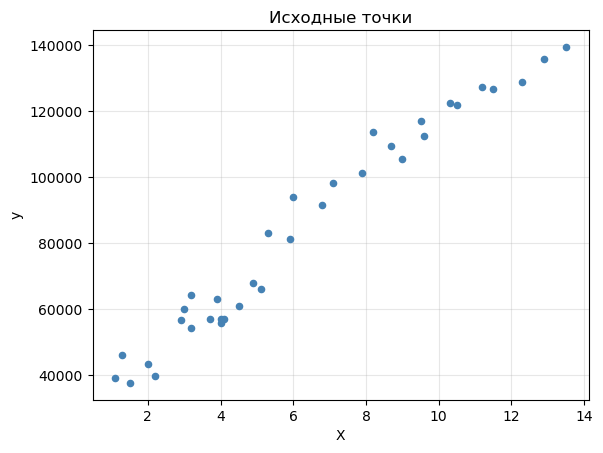

In [96]:
fig1, ax1 = plt.subplots()
plot_raw(X, y, ax1)

### 3. Реализация метода наименьших квадратов

In [ ]:
class Regression:
    def __init__(self):
        self.k = None
        self.b = None
        self.y_pred = None

    def fit(self, X, y):
        if X and isinstance(X[0], (list, tuple)):
            if len(X[0]) != 1:
                raise ValueError('Поддерживается только 1 признак')
            xs = [row[0] for row in X]
        else:
            xs = list(X)

        if len(xs) != len(y):
            raise ValueError('X и y разной длины')
        n = len(xs)
        if n < 2:
            raise ValueError('Нужно минимум 2 точки')

        # вычисляем коэффициенты для построяния прямой y = k * x + b, где a, b вычисляются по формулам ниже
        mean_x  = sum(xs) / n
        mean_y  = sum(y) / n
        mean_xy = sum(xi * yi for xi, yi in zip(xs, y)) / n
        mean_x2 = sum(xi * xi for xi in xs) / n

        denom = mean_x2 - mean_x ** 2
        if denom == 0:
            raise ValueError('Все X одинаковы — регрессия не определена')

        self.k = (mean_xy - mean_x * mean_y) / denom
        self.b = mean_y - self.k * mean_x

        self.y_pred = [self.k * xi + self.b for xi in xs]
        return self.y_pred

    def predict(self, x):
        if self.k is None:
            raise RuntimeError('Сначала вызовите fit()')
        if isinstance(x, (list, tuple)):
            return [self.k * xi + self.b for xi in x]
        return self.k * x + self.b

    def loss(self, y, y_pred=None):
        if y_pred is None:
            y_pred = self.y_pred
        return sum((yi - yp) ** 2 for yi, yp in zip(y, y_pred)) / len(y)

In [98]:
reg = Regression()
y_pred = reg.fit(X, y)

### 4. Отрисовка данных вместе с предсказаниями и квадратами из метода наименьших квадратов

In [99]:
def plot_with_line(xs, y, model, ax=None):
    if xs and isinstance(xs[0], (list, tuple)):
        xs = [row[0] for row in xs]
        
    ax = plot_raw(xs, y, ax, title='Точки и регрессионная прямая')
    x_min, x_max = min(xs), max(xs)
    ax.plot([x_min, x_max],
            [model.predict(x_min), model.predict(x_max)],
            color='red', linewidth=2, zorder=4,
            label=f'y = {model.k:.3f}x + {model.b:.3f}')
    ax.legend()
    return ax

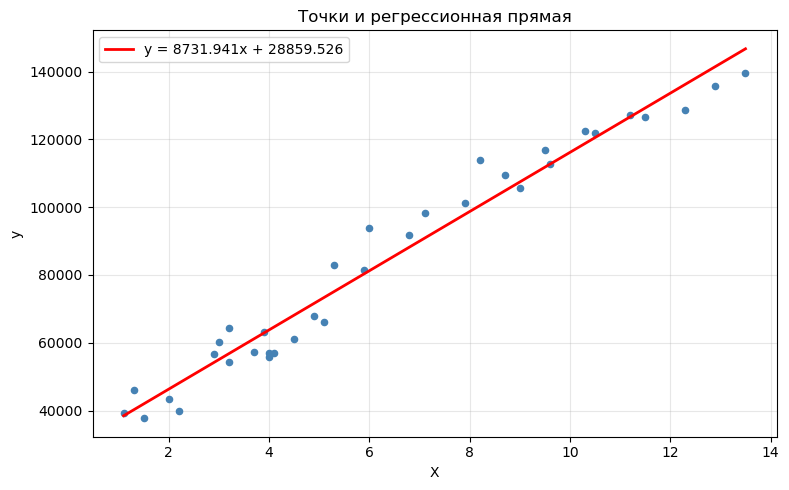

In [100]:
fig_line, ax_line = plt.subplots(figsize=(8, 5))
plot_with_line(X, y, reg, ax_line)
fig_line.tight_layout()
plt.show()

In [101]:
def plot_with_errors(xs, y, model, ax=None):
    if xs and isinstance(xs[0], (list, tuple)):
        xs = [row[0] for row in xs]

    ax = plot_raw(xs, y, ax, title='Квадраты ошибок')
    x_min, x_max = min(xs), max(xs)
    ax.plot([x_min, x_max],
            [model.predict(x_min), model.predict(x_max)],
            color='red', linewidth=1.5, zorder=4)

    y_min, y_max = ax.get_ylim()
    axis_height = ax.get_window_extent().height
    dpi = ax.figure.dpi
    error_centers = []
    square_sizes = []

    for xi, yi, yp in zip(xs, y, model.y_pred):
        side = abs(yi - yp)
        if side == 0:
            continue
        side_points = side / (y_max - y_min) * axis_height * 72 / dpi
        error_centers.append((xi, (yi + yp) / 2))
        square_sizes.append(side_points ** 2)

    if error_centers:
        squares = ax.scatter(
            [point[0] for point in error_centers],
            [point[1] for point in error_centers],
            s=square_sizes, marker='s',
            facecolors='orange', edgecolors='orange',
            alpha=0.3, linewidths=0.8, zorder=2
        )
        squares.set_hatch('//')

    return ax

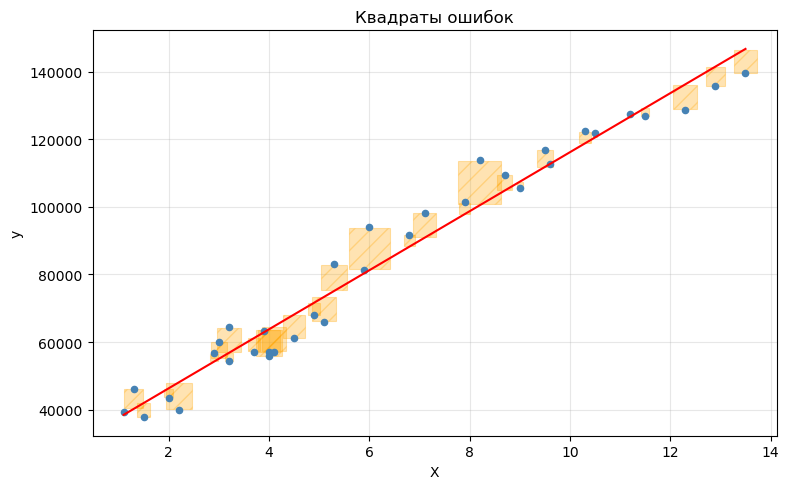

In [102]:
fig_errors, ax_errors = plt.subplots(figsize=(8, 5))
plot_with_errors(X, y, reg, ax_errors)
fig_errors.tight_layout()
plt.show()